# Portfolio Optimization — Introducing the Risk-Free Asset
### From Markowitz with short selling to the tangency portfolio and Tobin's separation

**Where we start:** You already know how to optimize risky portfolios with Markowitz, including short selling. Now imagine that your investment mandate has produced a risky portfolio, but you want to **change its risk without changing its relative holdings**.

Our questions today:
1. How do lending and borrowing change a portfolio's return and risk?
2. Does it matter which risky portfolio we combine with the risk-free asset?
3. How do we find the **maximum-Sharpe (tangency) portfolio**?
4. How do we achieve a **target volatility** or **target expected return**?
5. Why can investors with different risk preferences hold the same risky portfolio?

**Teaching assumptions:** the risk-free rate is known over the horizon; lending and borrowing are possible at the same rate; no fees or financing constraints. These assumptions are relaxed in the final discussion.

## 1. A portfolio already exists: how can we change its risk?

Suppose you have already selected a portfolio of stocks that satisfies your investment mandate. Instead of changing its stocks or their **relative weights**, you can:

- **Lend:** invest part of your wealth in a risk-free asset.
- **Stay fully invested:** put 100% of your wealth in your risky portfolio.
- **Borrow:** finance an investment larger than 100% in that same risky portfolio.

**Important distinction from the previous class:** shorting a *stock* creates negative exposure to that stock; a **negative risk-free weight** means borrowing money. These are not the same operation.

### Expected return and volatility of the mixed portfolio

Let **$w$ be the weight of the risk-free asset** and $1-w$ the weight of a previously chosen risky portfolio $R$.

$$E[R_p]=wr_f+(1-w)\mu_R$$

Start from the usual two-asset variance formula:

$$\sigma_p^2=w^2\sigma_f^2+(1-w)^2\sigma_R^2+2w(1-w)\operatorname{Cov}(R_f,R_R).$$

By assumption, the risk-free return is constant over the horizon, so $\sigma_f^2=0$ and $\operatorname{Cov}(R_f,R_R)=0$. Hence:

$$\boxed{\sigma_p=|1-w|\sigma_R}$$

For $1-w\geq 0$ the combinations trace a **straight line** in expected-return/volatility space. The absolute value matters: volatility cannot be negative.

| Risk-free weight $w$ | Risky weight $1-w$ | Meaning |
|---:|---:|---|
| 0.60 | 0.40 | Lend 60%, invest 40% in the risky portfolio |
| 0.00 | 1.00 | Invest 100% in the risky portfolio |
| −0.40 | 1.40 | Borrow 40%, invest 140% in the risky portfolio |

### Data and units

We reuse the original **2015–2019 stock universe** and the Boeing (BA) example. We work with **simple daily returns** so weighted portfolio returns are computed correctly, and annualize means with $252$ and volatilities with $\sqrt{252}$.

Some original tickers may now be unavailable from Yahoo Finance. We preserve the actual downloaded column names, exclude assets with too many missing observations, and use common dates. For a fully reproducible classroom exercise, you can set `LOCAL_PRICE_CSV` to a fixed adjusted-price dataset.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
import yfinance as yf


DAYS = 252
RF = 0.03                              # Annual arithmetic risk-free return
START, END = "2015-01-01", "2019-12-30"
MAX_MISSING = 0.10
LOCAL_PRICE_CSV = None                # Optional file with Date index and adjusted-price ticker columns
ASSETS = [
    'BA', 'BAX', 'BMY', 'CMCSA', 'CNP', 'CPB', 'DE', 'F', 'GE', 'HPQ',
    'JCI', 'JPM', 'KHC', 'LUV', 'MMC', 'MO', 'NI', 'PCAR', 'PSA', 'SEE',
    'T', 'TGT', 'TMO', 'TXT', 'VZ', 'ZION'
]

available = cp.installed_solvers()
SOLVER = next((s for s in ['CLARABEL', 'ECOS', 'SCS'] if s in available), None)
if SOLVER is None:
    raise RuntimeError(f"No suitable conic solver installed. Available: {available}")
print("CVXPY version:", cp.__version__, "| Solver:", SOLVER)

CVXPY version: 1.9.3 | Solver: CLARABEL


In [15]:
# Download adjusted closing prices from Yahoo Finance
prices = yf.download(
    ASSETS, start=START, end=END, auto_adjust=True
)['Close']

# Remove assets with more than 10% missing values
prices = prices.loc[:, prices.isna().mean() <= 0.10]

# Remove dates with missing prices
prices = prices.dropna()

# Calculate daily logarithmic returns
stock_returns = np.log(prices / prices.shift(1)).dropna()

# Annualized expected returns and covariance matrix
mu = stock_returns.mean().to_numpy() * 252
Sigma = stock_returns.cov().to_numpy() * 252

# Asset information
assets = prices.columns.tolist()
N = len(assets)

asset_stats = pd.DataFrame({
    'Expected return': mu,
    'Volatility': np.sqrt(np.diag(Sigma))
}, index=assets)

display(asset_stats.style.format('{:.2%}'))

[***********           23%                       ]  6 of 26 completed$SEE: Data doesn't exist for startDate = 1420088400, endDate = 1577682000
[**********************88%*****************      ]  23 of 26 completed$MMC: possibly delisted; no timezone found
[*********************100%***********************]  26 of 26 completed

2 Failed downloads:
['SEE']: Data doesn't exist for startDate = 1420088400, endDate = 1577682000
['MMC']: possibly delisted; no timezone found


,Expected return,Volatility
BA,21.29%,25.27%
BAX,16.30%,19.98%
BMY,4.08%,26.07%
CMCSA,10.93%,21.24%
CNP,7.01%,18.99%
CPB,5.23%,23.77%
DE,16.00%,25.36%
F,-4.01%,24.46%
GE,-12.81%,29.78%
HPQ,5.37%,29.80%


### Example: Boeing (BA) plus the risk-free asset

The stock has uncertain returns, while the risk-free asset has a known return by assumption. **Try lending and borrowing before looking at the calculations.** What happens to expected return and volatility as risky exposure increases?

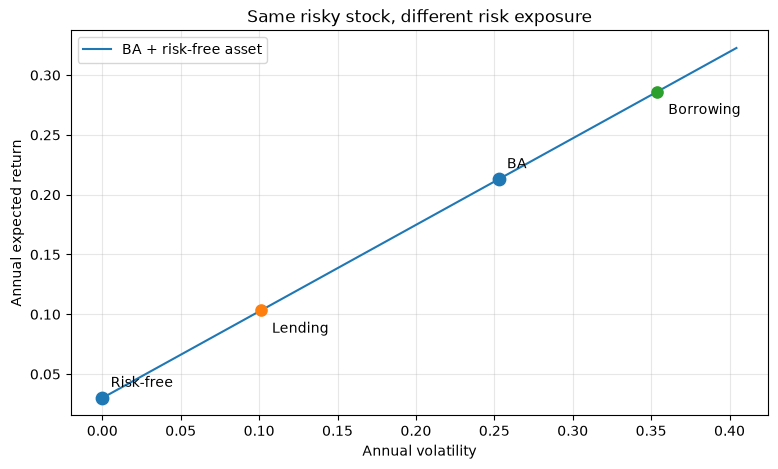

In [16]:
mu_BA = asset_stats.loc['BA', 'Expected return']
sigma_BA = asset_stats.loc['BA', 'Volatility']

w_rf_grid = np.linspace(-0.6, 1, 200)      # w = risk-free weight
risky_exposure = 1 - w_rf_grid
mix_mu = w_rf_grid * RF + risky_exposure * mu_BA
mix_sigma = np.abs(risky_exposure) * sigma_BA

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(mix_sigma, mix_mu, label='BA + risk-free asset')
ax.scatter([0, sigma_BA], [RF, mu_BA], s=80, zorder=3)
ax.annotate('Risk-free', (0, RF), xytext=(6, 8), textcoords='offset points')
ax.annotate('BA', (sigma_BA, mu_BA), xytext=(6, 8), textcoords='offset points')
for w, text_label in [(0.6, 'Lending'), (-0.4, 'Borrowing')]:
    ex = 1 - w
    point = (ex * sigma_BA, w * RF + ex * mu_BA)
    ax.scatter(*point, s=65, zorder=4)
    ax.annotate(text_label, point, xytext=(8, -16), textcoords='offset points')
ax.set(xlabel='Annual volatility', ylabel='Annual expected return',
       title='Same risky stock, different risk exposure')
ax.grid(alpha=0.3); ax.legend(); plt.show()


### Calculating portfolio weights for a target return or volatility

We combine a **risk-free asset** with a **risky portfolio** (BA in this exercise).

Let $w$ be the weight in the risk-free asset and $1-w$ the weight in BA.

#### 1. Target expected return

The portfolio's expected return is:

$$
\mu_p=wr_f+(1-w)\mu_R
$$

Rearranging:

$$
\mu_p=\mu_R+w(r_f-\mu_R)
$$

Solving for the risk-free weight:

$$
\boxed{w=\frac{\mu_p-\mu_R}{r_f-\mu_R}}
$$

Once $w$ is calculated, the weight invested in BA is $1-w$.

#### 2. Target volatility

Since the risk-free asset has zero variance and zero covariance with BA:

$$
\sigma_p^2=(1-w)^2\sigma_R^2
$$

Taking the square root:

$$
\sigma_p=|1-w|\sigma_R
$$

Assuming a **nonnegative investment in BA** ($1-w\geq0$):

$$
\sigma_p=(1-w)\sigma_R
$$

Solving for the risk-free weight:

$$
\boxed{w=1-\frac{\sigma_p}{\sigma_R}}
$$

#### Financial interpretation

- **$0<w<1$:** invest part of the wealth in the risk-free asset and the remainder in BA.
- **$w=0$:** invest all wealth in BA.
- **$w<0$:** borrow at the risk-free rate to invest more than 100% in BA.
- **$w=1$:** invest all wealth in the risk-free asset.

These formulas allow us to determine how much to lend, borrow, or invest in BA to achieve a specific expected return or volatility.


### Exercise 1 — Three choices for the same risky asset

Using the **estimated** expected return and volatility of BA from the downloaded data, find the risk-free weight $w$ and the risky weight $1-w$ that deliver:

**A.** An expected return of **14% annually**.

**B.** An expected return of **25% annually**. Is borrowing needed?

**C.** Volatility of **7% annually**, assuming a nonnegative risky exposure.

For each case, explain what the investor does with €100 of wealth. Do not assume the historical expected return of BA is exactly the same every time the data are downloaded.

In [17]:
def weights_for_return(target_return, risky_return, rf=RF):
    risky_weight = (target_return - rf) / (risky_return - rf)
    return 1 - risky_weight, risky_weight  # risk-free weight, risky weight

def weights_for_volatility(target_vol, risky_vol):
    risky_weight = target_vol / risky_vol     # nonnegative exposure branch
    return 1 - risky_weight, risky_weight

cases = [
    ('A: target return 14%', weights_for_return(.14, mu_BA)),
    ('B: target return 25%', weights_for_return(.25, mu_BA)),
    ('C: target volatility 7%', weights_for_volatility(.07, sigma_BA))
]
rows = []
for name, (w_rf, w_risky) in cases:
    rows.append({
        'Exercise': name, 'Risk-free weight': w_rf, 'Risky weight': w_risky,
        'Expected return': w_rf * RF + w_risky * mu_BA,
        'Volatility': abs(w_risky) * sigma_BA,
        'Interpretation': ('Borrow' if w_rf < 0 else 'Lend' if w_rf > 0 else 'All risky')
    })
exercise1 = pd.DataFrame(rows).set_index('Exercise')
display(exercise1.style.format({
    'Risk-free weight': '{:.1%}', 'Risky weight': '{:.1%}',
    'Expected return': '{:.2%}', 'Volatility': '{:.2%}'
}))

,Risk-free weight,Risky weight,Expected return,Volatility,Interpretation
Exercise,,,,,
A: target return 14%,39.9%,60.1%,14.00%,15.20%,Lend
B: target return 25%,-20.3%,120.3%,25.00%,30.40%,Borrow
C: target volatility 7%,72.3%,27.7%,8.07%,7.00%,Lend


**Takeaway:** with one fixed risky portfolio, the risk-free weight changes the **scale of exposure**, not the relative composition of the risky investments. But is every risky portfolio equally good for this purpose?

## 2. Does it matter which risky portfolio we choose?

Return to the risky-only Markowitz frontier you studied in the previous class. We compare two mandates:

- **Long-only:** no short positions in stocks.
- **Short selling allowed:** stock weights may be negative, but gross exposure is limited to **150%**.

Both have the same risky asset universe. For clarity, the main classroom comparisons below use the **long-only frontier**; the second frontier recalls what short selling changes.

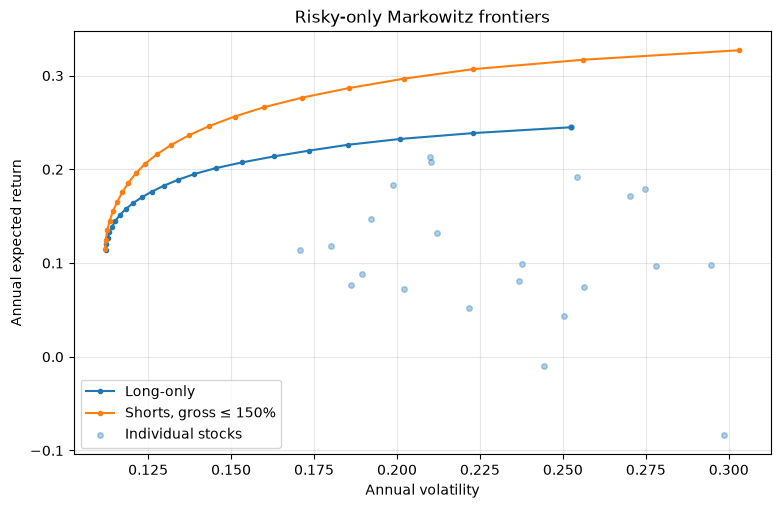

In [6]:
# CVXPY helper functions: every optimization uses the same annual inputs and same stock ordering.
def solve_checked(problem):
    val = problem.solve(solver=SOLVER)
    if problem.status not in ('optimal', 'optimal_inaccurate'):
        raise RuntimeError(f"Optimization failed: {problem.status}")
    return val

def mandate_constraints(z, gross_limit=1.0):
    cons = [cp.sum(z) == 1]
    if gross_limit == 1.0:
        cons += [z >= 0]
    else:
        cons += [cp.norm1(z) <= gross_limit]
    return cons

def portfolio_stats(weights):
    weights = np.asarray(weights, dtype=float).reshape(-1)
    return float(mu @ weights), float(np.sqrt(max(weights @ Sigma @ weights, 0)))

def risky_frontier(gross_limit, n_points=22):
    z = cp.Variable(N)
    base = mandate_constraints(z, gross_limit)
    variance = cp.quad_form(z, cp.psd_wrap(Sigma))
    solve_checked(cp.Problem(cp.Minimize(variance), base))
    w_gmv = np.asarray(z.value).reshape(-1).copy()
    ret_gmv, vol_gmv = portfolio_stats(w_gmv)

    solve_checked(cp.Problem(cp.Maximize(mu @ z), base))
    max_ret = float(mu @ z.value)
    targets = np.linspace(ret_gmv, max_ret - 1e-5 * max(1, abs(max_ret-ret_gmv)), n_points)
    points, weights = [], []
    for target in targets:
        solve_checked(cp.Problem(cp.Minimize(variance), base + [mu @ z >= target]))
        ww = np.asarray(z.value).reshape(-1).copy()
        rr, ss = portfolio_stats(ww)
        points.append((ss, rr))
        weights.append(ww)
    return {'points': np.asarray(points), 'weights': np.asarray(weights),
            'gmv': (vol_gmv, ret_gmv), 'gmv_weights': w_gmv}

frontiers = {
    'Long-only': risky_frontier(1.0),
    'Shorts, gross ≤ 150%': risky_frontier(1.5)
}

fig, ax = plt.subplots(figsize=(9, 5.5))
for name, data in frontiers.items():
    ax.plot(data['points'][:, 0], data['points'][:, 1], marker='.', label=name)
ax.scatter(np.sqrt(np.diag(Sigma)), mu, s=16, alpha=.35, label='Individual stocks')
ax.set(xlabel='Annual volatility', ylabel='Annual expected return',
       title='Risky-only Markowitz frontiers')
ax.grid(alpha=.3); ax.legend(); plt.show()


### Expected Return and Volatility: A Linear Relationship

Combining a risky portfolio with the risk-free asset gives:

$$
E[R_p]=r_f+(1-w)(\mu_R-r_f)
$$

$$
\sigma_p=(1-w)\sigma_R
$$

Assuming a nonnegative exposure to the risky portfolio, we can solve for $1-w$ and substitute:

$$
\boxed{E[R_p]=r_f+\underbrace{\frac{\mu_R-r_f}{\sigma_R}}_{\text{Sharpe ratio}}\sigma_p}
$$

This equation describes a **straight line** in the expected return–volatility diagram.

- **Intercept ($r_f$):** expected return with zero risk.
- **Slope (Sharpe ratio):** additional expected return per unit of volatility.

**Key insight:** A higher Sharpe ratio means a higher expected return for the same level of risk.


### Three portfolios, three different slopes

Select three portfolios from the **same** long-only efficient frontier. Combine each one with the risk-free asset. Each risky portfolio generates a different line:

$$E[R_p]=r_f+\underbrace{\frac{\mu_R-r_f}{\sigma_R}}_{\text{slope}}\sigma_p\qquad (\text{nonnegative risky exposure}).$$

**Question:** for the same portfolio volatility, which line gives the highest expected return? The answer depends on its **slope**, not simply on the original portfolio's expected return.

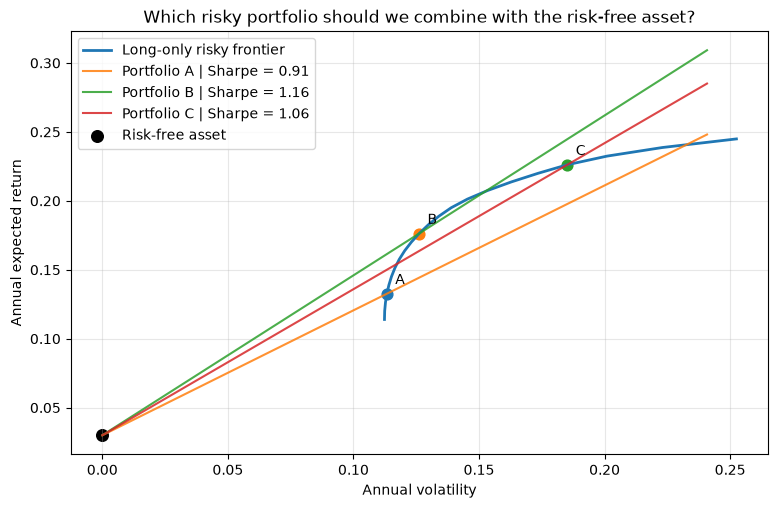

In [7]:
candidate_idx = [3, 10, 18]
candidates = frontiers['Long-only']['points'][candidate_idx]
sigma_line = np.linspace(0, max(candidates[:, 0]) * 1.30, 120)

fig, ax = plt.subplots(figsize=(9, 5.5))
base = frontiers['Long-only']['points']
ax.plot(base[:, 0], base[:, 1], label='Long-only risky frontier', lw=2)
for label, (sigma_i, mu_i) in zip(['A', 'B', 'C'], candidates):
    slope = (mu_i - RF) / sigma_i
    ax.plot(sigma_line, RF + slope * sigma_line,
            label=f'Portfolio {label} | Sharpe = {slope:.2f}', alpha=.85)
    ax.scatter(sigma_i, mu_i, s=60)
    ax.annotate(label, (sigma_i, mu_i), xytext=(6, 7), textcoords='offset points')
ax.scatter(0, RF, s=70, color='black', label='Risk-free asset')
ax.set(xlabel='Annual volatility', ylabel='Annual expected return',
       title='Which risky portfolio should we combine with the risk-free asset?')
ax.grid(alpha=.3); ax.legend(); plt.show()


### Which risky portfolio should we combine with the risk-free asset?

We can combine the risk-free asset with any risky portfolio. However, **not all portfolios offer the same return for a given level of risk**.

<img src="https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/Finance_Technology/Tema_4_CAPM/imgs/sharpe.PNG" width="650">

The **Sharpe ratio** measures the extra expected return per unit of risk:

$$
S_p=\frac{\mu_p-r_f}{\sigma_p}
$$

It represents the **slope of the line**. The higher the slope, the greater the expected return for the same volatility.

**Our goal:** Find the risky portfolio with the highest Sharpe ratio. This is called the **tangency portfolio**.



## CAPITAL MARKET LINE (CML) AND TOBIN'S SEPARATION

We consider an investor who wants to **maximize expected return while penalizing portfolio risk**, according to their risk aversion.

The optimization problem is:

$$
\begin{aligned}
\max_{w_0,w} \quad & w_0r_f+\mu^T w-\lambda w^T\Sigma w\\
\text{s.t.}\quad & w_0+\mathbf{1}^T w=1
\end{aligned}
$$

where:

- $w_0$ is the weight invested in the **risk-free asset**.
- $w$ is the vector of weights invested in the **risky assets**.
- $r_f$ is the risk-free rate.
- $\mu$ is the vector of expected returns of the risky assets.
- $\lambda$ is the investor's **risk-aversion coefficient**.
- $\Sigma$ is the covariance matrix of risky asset returns.

#### Simplifying the optimization problem

We can eliminate $w_0$ using the budget constraint:

1. Solve for $w_0$:

   $$w_0=1-\mathbf{1}^T w$$

2. Substitute into the objective function.

3. Remove the constant $r_f$ and simplify:

$$
\max_w \quad w^T\pi-\lambda w^T\Sigma w
$$

where $\pi=\mu-r_f\mathbf{1}$ is the vector of **expected risk premiums**.

#### Finding the optimal weights

We take the first derivative with respect to $w$ and set it equal to zero:

$$
\pi-2\lambda\Sigma w=0
$$

Solving for $w$, assuming $\Sigma$ is invertible, gives:

$$
\boxed{
w^*=
\underbrace{\frac{1}{2\lambda}}_{\text{Risk exposure}}
\;\underbrace{\Sigma^{-1}\pi}_{\text{Relative portfolio composition}}
}
$$

The optimal weight in the risk-free asset is:

$$
w_0^*=1-\mathbf{1}^T w^*
$$

Therefore:

$$
\boxed{
w_0^*=1-\frac{1}{2\lambda}\mathbf{1}^T\Sigma^{-1}\pi
}
$$

**Financial interpretation:** The risk premiums and covariance matrix determine the relative positions in risky assets, while the investor's risk aversion determines how much those positions are scaled up or down.

This result provides the intuition behind **Tobin's separation theorem**.



### Summary: Tobin's Separation Theorem

So far, we have learned that:

1. **Portfolio selection with risky assets:** Using Markowitz's framework, investors choose efficient portfolios based on expected returns, risk, and their risk preferences.

2. **Introducing the risk-free asset:** Investors can combine risky portfolios with the risk-free asset to adjust their exposure to risk.

3. **The tangency portfolio:** Among all risky portfolios, the tangency portfolio offers the highest Sharpe ratio. Under the model's assumptions, it is the same for all investors, regardless of their risk aversion.

4. **The Capital Market Line (CML):** By combining the tangency portfolio with the risk-free asset, investors can select different levels of expected return and risk along the CML.

### Tobin's Separation Theorem

**Tobin's Separation Theorem states that portfolio selection can be divided into two independent decisions:**

1. **Portfolio composition:** Identify the tangency portfolio, which maximizes the Sharpe ratio.
2. **Risk exposure:** Decide how much to invest in the tangency portfolio and how much to lend or borrow at the risk-free rate, according to the investor's risk aversion.

### Key Assumptions

This result relies on several assumptions:

- Investors make decisions based on expected return and variance.
- Investors share the same expectations about returns, volatilities, and correlations.
- Investors can lend and borrow at the same risk-free rate.
- There are no additional investment constraints that prevent the required portfolio combinations.

**Key takeaway:** Investors with different risk preferences can hold the same risky portfolio. What changes is their exposure to it, not its relative composition.


## 3. Finding the maximum-Sharpe (tangency) portfolio

The tangency portfolio maximizes the positive Sharpe ratio among admissible risky portfolios:

$$\max_{z}\frac{\mu^\top z-r_f}{\sqrt{z^\top\Sigma z}},\qquad \mathbf{1}^\top z=1.$$

We first use a **long-only mandate**. We then show how the answer can change if short positions are allowed with a gross-exposure limit. Each tangency portfolio is compared with its **matching risky frontier**.

CVXPY cannot maximize this ratio directly under its standard convexity rules. For positive excess return, we instead fix the excess return of an **unnormalized** vector at 1, minimize its variance, and then normalize the vector to sum to 1.

In [19]:

# Portfolio weights
weights = cp.Variable(N)

# Portfolio expected excess return and volatility
excess_return = (mu - RF) @ weights
volatility = cp.sqrt(cp.quad_form(weights, cp.psd_wrap(Sigma)))

# Constraints
constraints = [
    weights >= 0,
    cp.sum(weights) == 1
]

# Objective: maximize the Sharpe ratio
objective = cp.Maximize(excess_return / volatility)

# Define and solve the problem
problem = cp.Problem(objective, constraints)
result = problem.solve()


DCPError: Problem does not follow DCP rules. Specifically:
The objective is not DCP. Its following subexpressions are not:
PowerApprox(QuadForm(var1948, psd_wrap([[0.06 0.02 ... 0.01 0.03]
 [0.02 0.04 ... 0.01 0.02]
 ...
 [0.01 0.01 ... 0.03 0.01]
 [0.03 0.02 ... 0.01 0.07]])), 0.5)


### Maximizing the Sharpe Ratio with CVXPY

The **Sharpe ratio** measures the expected excess return per unit of portfolio risk:

$$
S_p=\frac{\mu_p-r_f}{\sigma_p}
$$

where:
- $\mu_p$ is the portfolio's expected return.
- $r_f$ is the risk-free rate.
- $\sigma_p$ is the portfolio's volatility (standard deviation).

For a portfolio of risky assets, the optimization problem is:

$$
\max_w \quad \frac{\pi^T w}{\sqrt{w^T\Sigma w}}
$$

subject to:

$$
\mathbf{1}^T w=1,\qquad w\geq0
$$

where $\pi=\mu-r_f\mathbf{1}$ is the vector of expected risk premiums.

#### Why can't CVXPY solve this formulation directly?

Although portfolio volatility $\sqrt{w^T\Sigma w}$ is a **convex function**, maximizing the ratio of a linear function to a convex function does not satisfy CVXPY's standard Disciplined Convex Programming (DCP) rules.

Fortunately, we can reformulate the problem as a convex optimization problem.

#### Reformulating the problem

**Step 1. Introduce a new variable**

The Sharpe ratio is unchanged when all portfolio positions are multiplied by the same positive number:

$$
S(\alpha w)=S(w),\qquad \alpha>0
$$

We can therefore introduce $x=\alpha w$ and choose its scale so that the expected excess return equals 1:

$$
\pi^T x=1
$$

**Step 2. Simplify the objective**

With the numerator fixed at 1, maximizing the Sharpe ratio is equivalent to minimizing portfolio variance:

$$
\max_x \frac{1}{\sqrt{x^T\Sigma x}}
\quad\Longleftrightarrow\quad
\min_x x^T\Sigma x
$$

**Step 3. Solve the convex problem**

We obtain:

$$
\boxed{
\begin{aligned}
\min_x \quad & x^T\Sigma x\\
\text{s.t.}\quad & \pi^T x=1\\
& x\geq0
\end{aligned}
}
$$

This is a **convex quadratic optimization problem** that CVXPY can solve.

#### Recovering the portfolio weights

The solution $x^*$ is not yet normalized to sum to 1. We recover the tangency portfolio weights as:

$$
\boxed{w^*=\frac{x^*}{\mathbf{1}^T x^*}}
$$

**Key takeaway:** Instead of maximizing the Sharpe ratio directly, we minimize portfolio variance while fixing the expected excess return. Both formulations produce the same tangency portfolio under the assumptions that $\Sigma$ is positive definite and at least one admissible portfolio has positive expected excess return.


In [20]:

# Decision variable
x = cp.Variable(N)

# Portfolio variance
risk = cp.quad_form(x, cp.psd_wrap(Sigma))

# Expected risk premiums
pi = mu - RF

# Constraints
constraints = [
    pi @ x == 1,  # Fix expected excess return to 1
    x >= 0        # No short selling
]

# Objective: minimize variance
objective = cp.Minimize(risk)

# Define and solve the problem
problem = cp.Problem(objective, constraints)
result = problem.solve(solver=cp.CLARABEL)

# Normalize portfolio weights
if problem.status == 'optimal':
    weights_tangency = x.value / x.value.sum()
else:
    print("Optimization status:", problem.status)


In [21]:

# Remove negligible weights (only for display)
weights_display = np.where(weights_tangency > 1e-4,
                           weights_tangency, 0)

# Select assets with positive weights
selected_assets = np.array(assets)[weights_display > 0]
selected_weights = weights_display[weights_display > 0]

# Tangency portfolio expected return and volatility
return_tangency = mu @ weights_tangency
vol_tangency = np.sqrt(weights_tangency @ Sigma @ weights_tangency)

# Sharpe ratio
sharpe_tangency = (return_tangency - RF) / vol_tangency

# Display results
print(f"Expected annual return: {return_tangency:.2%}")
print(f"Annual volatility: {vol_tangency:.2%}")
print(f"Sharpe ratio: {sharpe_tangency:.3f}")

pd.Series(selected_weights, index=selected_assets).round(3)


Expected annual return: 17.19%
Annual volatility: 13.99%
Sharpe ratio: 1.014


BA     0.174
BAX    0.137
JPM    0.225
NI     0.242
TGT    0.055
TMO    0.166
dtype: float64

**Financial interpretation:** the tangency portfolio is not necessarily the highest-return stock portfolio or the minimum-volatility portfolio. It is the one with the greatest **expected excess return per unit of volatility**.

**Mandate matters:** allowing stock shorts can change the tangency portfolio. Borrowing at the risk-free rate, by contrast, lets an investor **scale a selected risky portfolio** without changing its relative stock holdings.

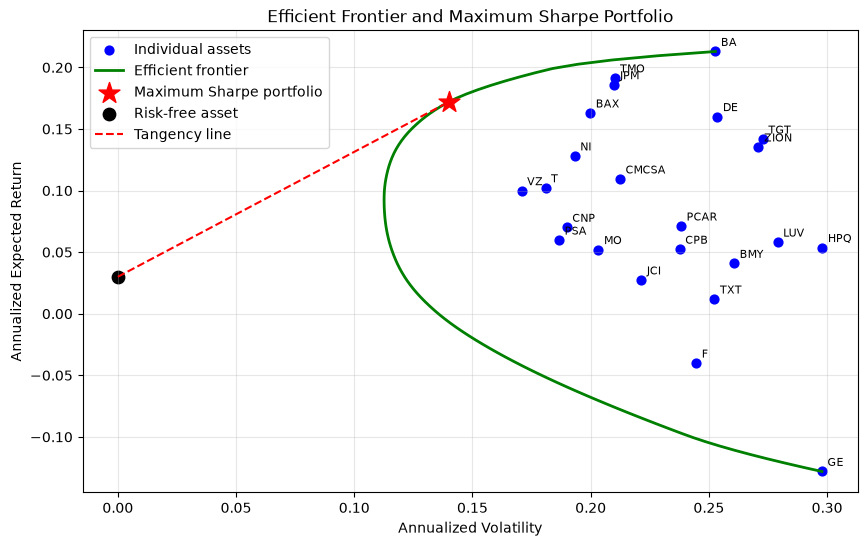

In [23]:

# Recalculate the long-only efficient frontier
target_returns = np.linspace(mu.min(), mu.max(), 100)

frontier_vol = []
frontier_ret = []

for target in target_returns:
    w = cp.Variable(N)

    problem = cp.Problem(
        cp.Minimize(cp.quad_form(w, cp.psd_wrap(Sigma))),
        [
            cp.sum(w) == 1,
            w >= 0,
            mu @ w == target
        ]
    )

    problem.solve(solver=cp.CLARABEL)

    if problem.status == 'optimal':
        weights = w.value
        frontier_vol.append(np.sqrt(weights @ Sigma @ weights))
        frontier_ret.append(mu @ weights)

# Tangency portfolio statistics
return_tangency = mu @ weights_tangency
vol_tangency = np.sqrt(weights_tangency @ Sigma @ weights_tangency)

# Plot
plt.figure(figsize=(10, 6))

plt.scatter(np.sqrt(np.diag(Sigma)), mu,
            color='blue', s=40, label='Individual assets')

for i, asset in enumerate(assets):
    plt.annotate(asset, (np.sqrt(Sigma[i, i]), mu[i]),
                 xytext=(4, 4), textcoords='offset points', fontsize=8)

plt.plot(frontier_vol, frontier_ret,
         color='green', linewidth=2, label='Efficient frontier')

plt.scatter(vol_tangency, return_tangency,
            color='red', marker='*', s=250,
            label='Maximum Sharpe portfolio', zorder=5)

plt.scatter(0, RF, color='black', s=80, label='Risk-free asset')

plt.plot([0, vol_tangency], [RF, return_tangency],
         'r--', label='Tangency line')

plt.xlabel('Annualized Volatility')
plt.ylabel('Annualized Expected Return')
plt.title('Efficient Frontier and Maximum Sharpe Portfolio')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**What have we achieved?** We did not redesign the relative stock weights to meet the investor's risk tolerance. We first selected the tangency portfolio and then adjusted its **scale** using risk-free lending or borrowing.

This two-step result applies when the final combination is allowed by the investor's mandate and borrowing assumptions. A global leverage cap may restrict how far the tangency line can be extended.


## Exercise — Portfolio Management for a Client

You are a portfolio manager at an investment advisory firm. A client asks you to construct a portfolio that **maximizes expected return while keeping annual volatility at or below 12%**.

You can invest in:

- **Stocks:** AAPL, MSFT, JPM, JNJ, XOM and PG.
- **Risk-free asset:** Annual interest rate of 3%.

The client allows borrowing at the risk-free rate but does not permit short selling of individual stocks.

### Tasks

**1. Download and prepare the data**

Download adjusted daily closing prices from Yahoo Finance for the period **January 1, 2019, to December 31, 2025**.

Calculate daily returns and estimate annualized expected returns, volatilities and the covariance matrix.

**2. Calculate the tangency portfolio**

Find the portfolio of risky assets that maximizes the Sharpe ratio, subject to the no-short-selling constraint.

Report the optimal weights, expected annual return, volatility and Sharpe ratio.

**3. Construct the client's portfolio**

The client requires a maximum annual volatility of **12%**.

- Calculate the proportion invested in the tangency portfolio and the risk-free asset.
- Determine whether the client should lend or borrow at the risk-free rate.
- Calculate the expected annual return of the final portfolio.
- Report the final weights of all assets, including the risk-free asset.

**4. Visualize the results**

Create a risk–return chart showing the individual stocks, the Markowitz efficient frontier, the risk-free asset, the tangency portfolio, the Capital Allocation Line and the client's optimal portfolio.

**5. Financial interpretation**

Briefly explain:

- Why is the tangency portfolio appropriate for this client?
- How would the allocation change if the client's maximum volatility were reduced to 6%?
- Would the composition of the tangency portfolio change?

**Objective:** Demonstrate how Tobin's Separation Theorem allows investors to adjust portfolio risk without changing the relative composition of the risky portfolio.
